# Car Information Dataset
Dataset: https://www.kaggle.com/datasets/tawfikelmetwally/automobile-dataset?select=Automobile.csv

Main question of this research: How does the country of origin (USA, Japan, Europe) affect fuel efficiency (MPG)?

Additional question: are the most fuel-efficient cars (MPG > 30) mostly made in Japan?

In [1]:
# Import Python Libraries
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
data_path = 'input/cars.csv'
df = pd.read_csv(data_path)
# cars.csv faylida ustun nomlari (header) allaqachon bor:
# name, mpg, cylinders, displacement, horsepower, weight, acceleration, model_year, origin
df.head()

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


In [3]:
df.tail(10)

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
388,chrysler lebaron medallion,26.0,4,156.0,92.0,2585,14.5,82,usa
389,ford granada l,22.0,6,232.0,112.0,2835,14.7,82,usa
390,toyota celica gt,32.0,4,144.0,96.0,2665,13.9,82,japan
391,dodge charger 2.2,36.0,4,135.0,84.0,2370,13.0,82,usa
392,chevrolet camaro,27.0,4,151.0,90.0,2950,17.3,82,usa
393,ford mustang gl,27.0,4,140.0,86.0,2790,15.6,82,usa
394,vw pickup,44.0,4,97.0,52.0,2130,24.6,82,europe
395,dodge rampage,32.0,4,135.0,84.0,2295,11.6,82,usa
396,ford ranger,28.0,4,120.0,79.0,2625,18.6,82,usa
397,chevy s-10,31.0,4,119.0,82.0,2720,19.4,82,usa


In [4]:
df['displacement'].dtype

dtype('float64')

In [5]:
df.dtypes

name             object
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin           object
dtype: object

In [6]:
#Group data using rank
df_rank = df.groupby(['origin'])
df_rank['mpg'].mean()

origin
europe    27.891429
japan     30.450633
usa       20.083534
Name: mpg, dtype: float64

In [7]:
df.replace("?", np.nan, inplace = True)
df['horsepower'] = df['horsepower'].astype('float')
df_sub = df[df['mpg'] > 30]
df_sub

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
53,toyota corolla 1200,31.0,4,71.0,65.0,1773,19.0,71,japan
54,datsun 1200,35.0,4,72.0,69.0,1613,18.0,71,japan
129,datsun b210,31.0,4,79.0,67.0,1950,19.0,74,japan
131,toyota corolla 1200,32.0,4,71.0,65.0,1836,21.0,74,japan
144,toyota corona,31.0,4,76.0,52.0,1649,16.5,74,japan
...,...,...,...,...,...,...,...,...,...
390,toyota celica gt,32.0,4,144.0,96.0,2665,13.9,82,japan
391,dodge charger 2.2,36.0,4,135.0,84.0,2370,13.0,82,usa
394,vw pickup,44.0,4,97.0,52.0,2130,24.6,82,europe
395,dodge rampage,32.0,4,135.0,84.0,2295,11.6,82,usa


In [8]:
df_f = df[ df['origin'] == 'japan']
df_f

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
14,toyota corona mark ii,24.0,4,113.0,95.0,2372,15.0,70,japan
18,datsun pl510,27.0,4,97.0,88.0,2130,14.5,70,japan
29,datsun pl510,27.0,4,97.0,88.0,2130,14.5,71,japan
31,toyota corona,25.0,4,113.0,95.0,2228,14.0,71,japan
53,toyota corolla 1200,31.0,4,71.0,65.0,1773,19.0,71,japan
...,...,...,...,...,...,...,...,...,...
382,toyota corolla,34.0,4,108.0,70.0,2245,16.9,82,japan
383,honda civic,38.0,4,91.0,67.0,1965,15.0,82,japan
384,honda civic (auto),32.0,4,91.0,67.0,1965,15.7,82,japan
385,datsun 310 gx,38.0,4,91.0,67.0,1995,16.2,82,japan


In [10]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [11]:
df['origin'].value_counts()

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

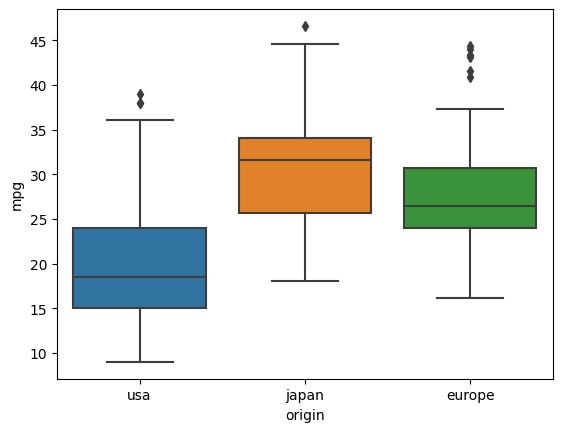

In [12]:
sns.boxplot(x='origin', y='mpg', data=df)
plt.show()